# Research Results — Agentic MARL Trading System
## Enhancing Algorithmic Financial Decision-Making through Agentic Systems and Multi-Agent Reinforcement Learning

**Student:** Lee Wei Wen | 24212787  
**Supervisor:** TS. DR. MOHD SHAHRUL NIZAM MOHD DANURI  
**Programme:** Master in Data Science

---
This notebook presents the empirical findings for all three research questions (RQ1, RQ2, RQ3).

## Setup

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

os.chdir('C:/Users/User/MARL')

plt.rcParams['figure.figsize']  = (12, 5)
plt.rcParams['axes.grid']       = True
plt.rcParams['grid.alpha']      = 0.3
plt.rcParams['font.size']       = 11

COLORS = {
    'buy_and_hold'        : '#636EFA',
    'MARL-no-coordinator' : '#EF553B',
    'MARL+LLM'           : '#00CC96',
}

print('Setup complete.')

Setup complete.


## 1. Load Results

In [9]:
# Load multi-seed results
multi_seed = pd.read_csv('results/logs/multi_seed_results.csv')
summary    = pd.read_csv('results/logs/multi_seed_summary.csv')

print('Multi-seed results shape:', multi_seed.shape)
print('Strategies:', multi_seed['strategy'].unique().tolist())
print()
print(summary[['strategy','mean_return','mean_sharpe','mean_drawdown','mean_final_value']].to_string(index=False))

Multi-seed results shape: (30, 7)
Strategies: ['buy_and_hold', 'MARL-no-coordinator', 'MARL+LLM']

           strategy  mean_return  mean_sharpe  mean_drawdown  mean_final_value
       buy_and_hold    -0.030426     0.058843       0.306767      96957.436230
MARL-no-coordinator     0.471949     1.223484       0.463961     147194.925765
           MARL+LLM     0.533480     1.297496       0.476258     153347.981458


## 2. Performance Comparison Table
**RQ3:** How does this combined approach compare to simpler baseline strategies?

In [10]:
# Format comparison table
table = summary[['strategy','mean_return','std_return',
                 'mean_sharpe','std_sharpe',
                 'mean_drawdown','std_drawdown',
                 'mean_final_value']].copy()

table['mean_return']  = (table['mean_return'] * 100).round(2).astype(str) + '%'
table['std_return']   = (table['std_return']  * 100).round(2).astype(str) + '%'
table['mean_sharpe']  = table['mean_sharpe'].round(4)
table['std_sharpe']   = table['std_sharpe'].round(4)
table['mean_drawdown']= (table['mean_drawdown'] * 100).round(2).astype(str) + '%'
table['std_drawdown'] = (table['std_drawdown']  * 100).round(2).astype(str) + '%'
table['mean_final_value'] = table['mean_final_value'].apply(lambda x: f'${x:,.2f}')

table.columns = ['Strategy','Mean Return','Std Return',
                 'Mean Sharpe','Std Sharpe',
                 'Mean Drawdown','Std Drawdown','Mean Final Value']
table = table.reset_index(drop=True)
print('=== PERFORMANCE COMPARISON TABLE (10 seeds) ===')
print(table.to_string(index=False))

=== PERFORMANCE COMPARISON TABLE (10 seeds) ===
           Strategy Mean Return Std Return  Mean Sharpe  Std Sharpe Mean Drawdown Std Drawdown Mean Final Value
       buy_and_hold      -3.04%       0.0%       0.0588      0.0000        30.68%         0.0%       $96,957.44
MARL-no-coordinator      47.19%      60.2%       1.2235      1.3538         46.4%        9.65%      $147,194.93
           MARL+LLM      53.35%     66.97%       1.2975      1.3993        47.63%       10.42%      $153,347.98


## 3. Mean Return Comparison (Bar Chart)

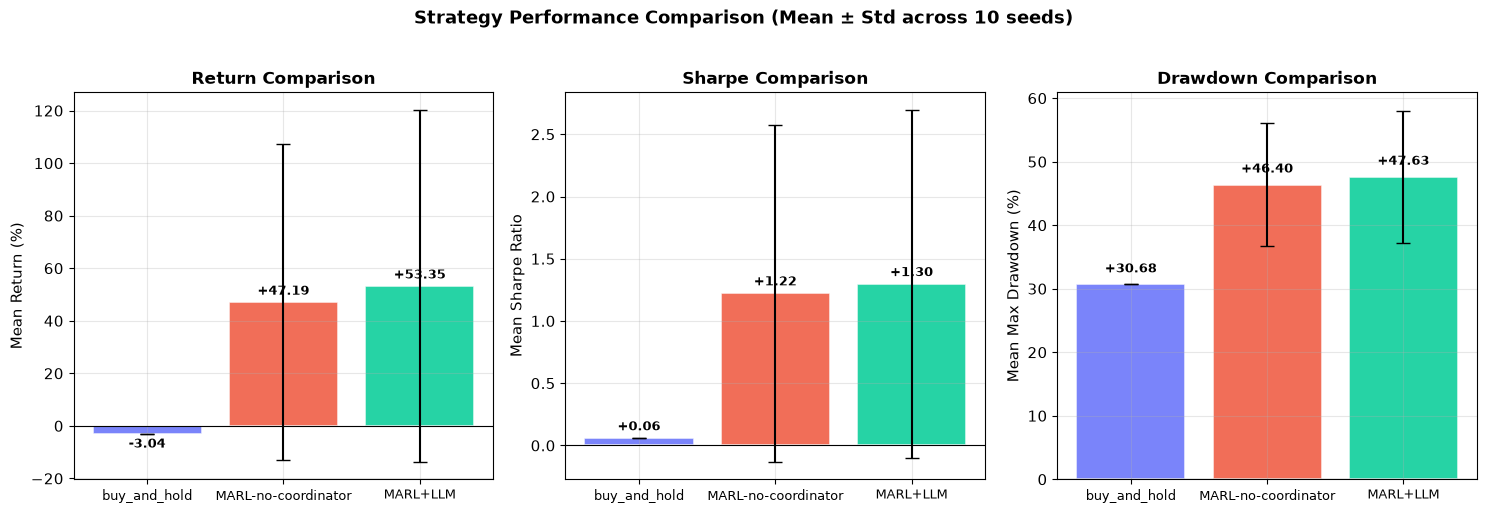

Saved → results/logs/comparison_bar.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ('mean_return',   'Mean Return (%)',       100,  'Return'),
    ('mean_sharpe',   'Mean Sharpe Ratio',     1,    'Sharpe'),
    ('mean_drawdown', 'Mean Max Drawdown (%)', 100,  'Drawdown'),
]

for ax, (col, ylabel, scale, label) in zip(axes, metrics):
    strategies = summary['strategy'].tolist()
    values     = (summary[col] * scale).tolist()
    std_col    = col.replace('mean_', 'std_')
    errors     = (summary[std_col] * scale).tolist() if std_col in summary.columns else None
    colors     = [COLORS.get(s, '#888') for s in strategies]

    bars = ax.bar(strategies, values, color=colors,
                  alpha=0.85, edgecolor='white', linewidth=1.2,
                  yerr=errors, capsize=5, error_kw={'linewidth':1.5})

    ax.set_title(f'{label} Comparison', fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.set_xticklabels(
        [s.replace('-', '-') for s in strategies],
        fontsize=9
    )
    ax.axhline(0, color='black', linewidth=0.8)

    # Value labels
    for bar, val in zip(bars, values):
        offset = max(abs(v) for v in values) * 0.03
        va     = 'bottom' if val >= 0 else 'top'
        sign   = '+' if val > 0 else ''
        ax.text(bar.get_x() + bar.get_width()/2,
                val + (offset if val >= 0 else -offset),
                f'{sign}{val:.2f}', ha='center', va=va,
                fontsize=9, fontweight='bold')

plt.suptitle('Strategy Performance Comparison (Mean ± Std across 10 seeds)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('results/logs/comparison_bar.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → results/logs/comparison_bar.png')

## 4. Per-Seed Results — Distribution (Box Plot)

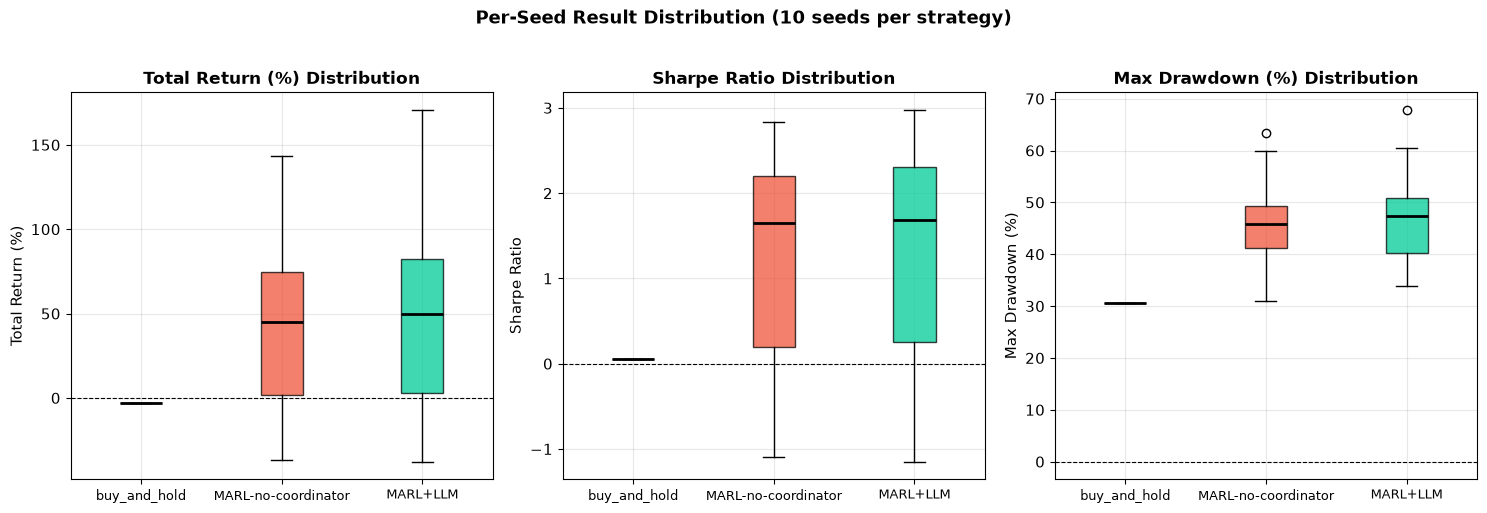

Saved → results/logs/distribution_boxplot.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ('total_return',  'Total Return (%)', 100),
    ('sharpe_ratio',  'Sharpe Ratio',     1),
    ('max_drawdown',  'Max Drawdown (%)', 100),
]

strategies = multi_seed['strategy'].unique().tolist()

for ax, (col, ylabel, scale) in zip(axes, metrics):
    data   = [multi_seed[multi_seed['strategy']==s][col].values * scale
              for s in strategies]
    colors = [COLORS.get(s, '#888') for s in strategies]

    bp = ax.boxplot(data, patch_artist=True, notch=False,
                    medianprops=dict(color='black', linewidth=2))

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_xticklabels(
        [s.replace('-', '-') for s in strategies],
        fontsize=9
    )
    ax.set_title(f'{ylabel} Distribution', fontsize=12, fontweight='bold')
    ax.set_ylabel(ylabel)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

plt.suptitle('Per-Seed Result Distribution (10 seeds per strategy)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('results/logs/distribution_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → results/logs/distribution_boxplot.png')

## 5. RQ2 — Does LLM Coordination Add Value?
Comparing MARL-no-coordinator vs MARL+LLM across all seeds.

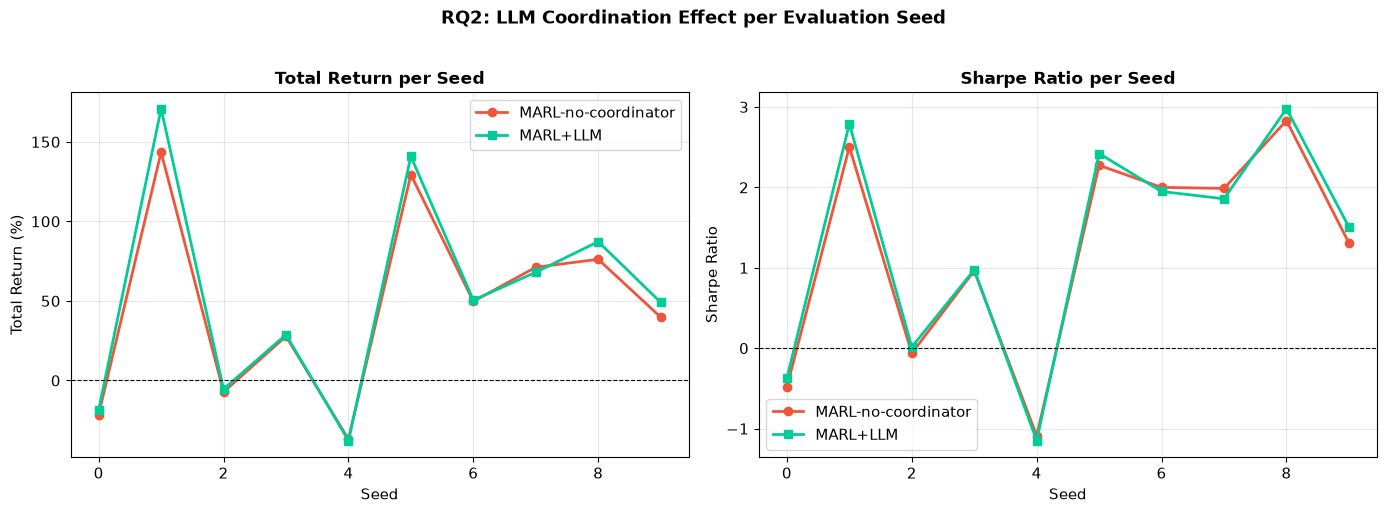

LLM+MARL outperforms MARL-no-coordinator:
  Return: 8/10 seeds
  Sharpe: 7/10 seeds
Saved → results/logs/rq2_llm_effect.png


In [13]:
marl     = multi_seed[multi_seed['strategy']=='MARL-no-coordinator'].reset_index(drop=True)
llm      = multi_seed[multi_seed['strategy']=='MARL+LLM'].reset_index(drop=True)
seeds    = marl['seed'].values

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Return per seed
axes[0].plot(seeds, marl['total_return']*100, 'o-',
             color=COLORS['MARL-no-coordinator'],
             label='MARL-no-coordinator', linewidth=2, markersize=6)
axes[0].plot(seeds, llm['total_return']*100, 's-',
             color=COLORS['MARL+LLM'],
             label='MARL+LLM', linewidth=2, markersize=6)
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].set_title('Total Return per Seed', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Seed')
axes[0].set_ylabel('Total Return (%)')
axes[0].legend()

# Sharpe per seed
axes[1].plot(seeds, marl['sharpe_ratio'], 'o-',
             color=COLORS['MARL-no-coordinator'],
             label='MARL-no-coordinator', linewidth=2, markersize=6)
axes[1].plot(seeds, llm['sharpe_ratio'], 's-',
             color=COLORS['MARL+LLM'],
             label='MARL+LLM', linewidth=2, markersize=6)
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Sharpe Ratio per Seed', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Seed')
axes[1].set_ylabel('Sharpe Ratio')
axes[1].legend()

plt.suptitle('RQ2: LLM Coordination Effect per Evaluation Seed',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('results/logs/rq2_llm_effect.png', dpi=150, bbox_inches='tight')
plt.show()

# Count wins
llm_wins_return = (llm['total_return'] > marl['total_return']).sum()
llm_wins_sharpe = (llm['sharpe_ratio'] > marl['sharpe_ratio']).sum()
print(f'LLM+MARL outperforms MARL-no-coordinator:')
print(f'  Return: {llm_wins_return}/10 seeds')
print(f'  Sharpe: {llm_wins_sharpe}/10 seeds')
print(f'Saved → results/logs/rq2_llm_effect.png')

## 6. RQ1 — Does Company-Specific Sentiment Add Value?
SHAP analysis of the sentiment agent — which features drive decisions.

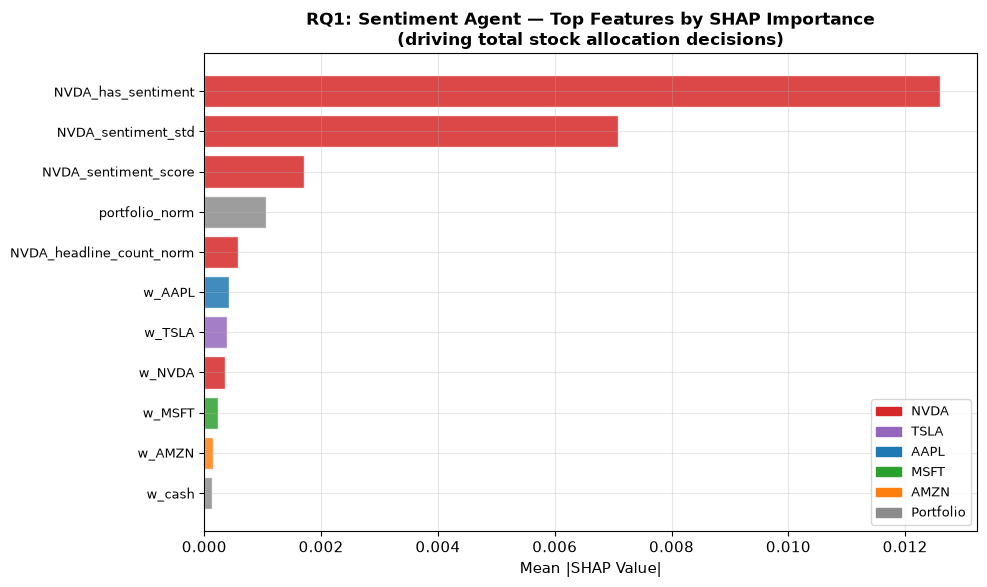

Saved → results/logs/rq1_shap_importance.png

Key finding:
NVDA features dominate sentiment agent decisions.
has_sentiment (signal freshness) > sentiment_score (score value)
Agent learned to trust fresh signals over stale forward-filled scores.


In [14]:
shap_df = pd.read_csv('results/logs/shap/sentiment_agent_shap.csv')
shap_df = shap_df[shap_df['mean_abs_shap'] > 0].head(15)

fig, ax = plt.subplots(figsize=(10, 6))

colors = []
for feat in shap_df['feature']:
    if 'NVDA' in feat:   colors.append('#d62728')
    elif 'TSLA' in feat: colors.append('#9467bd')
    elif 'AAPL' in feat: colors.append('#1f77b4')
    elif 'MSFT' in feat: colors.append('#2ca02c')
    elif 'AMZN' in feat: colors.append('#ff7f0e')
    else:                colors.append('#8c8c8c')

ax.barh(range(len(shap_df)), shap_df['mean_abs_shap'].values[::-1],
        color=colors[::-1], alpha=0.85, edgecolor='white')
ax.set_yticks(range(len(shap_df)))
ax.set_yticklabels(shap_df['feature'].values[::-1], fontsize=9)
ax.set_xlabel('Mean |SHAP Value|')
ax.set_title('RQ1: Sentiment Agent — Top Features by SHAP Importance\n'
             '(driving total stock allocation decisions)',
             fontsize=12, fontweight='bold')

# Legend
patches = [
    mpatches.Patch(color='#d62728', label='NVDA'),
    mpatches.Patch(color='#9467bd', label='TSLA'),
    mpatches.Patch(color='#1f77b4', label='AAPL'),
    mpatches.Patch(color='#2ca02c', label='MSFT'),
    mpatches.Patch(color='#ff7f0e', label='AMZN'),
    mpatches.Patch(color='#8c8c8c', label='Portfolio'),
]
ax.legend(handles=patches, loc='lower right', fontsize=9)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('results/logs/rq1_shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → results/logs/rq1_shap_importance.png')

print('\nKey finding:')
print('NVDA features dominate sentiment agent decisions.')
print('has_sentiment (signal freshness) > sentiment_score (score value)')
print('Agent learned to trust fresh signals over stale forward-filled scores.')

## 7. SHAP — Sentiment Importance by Ticker

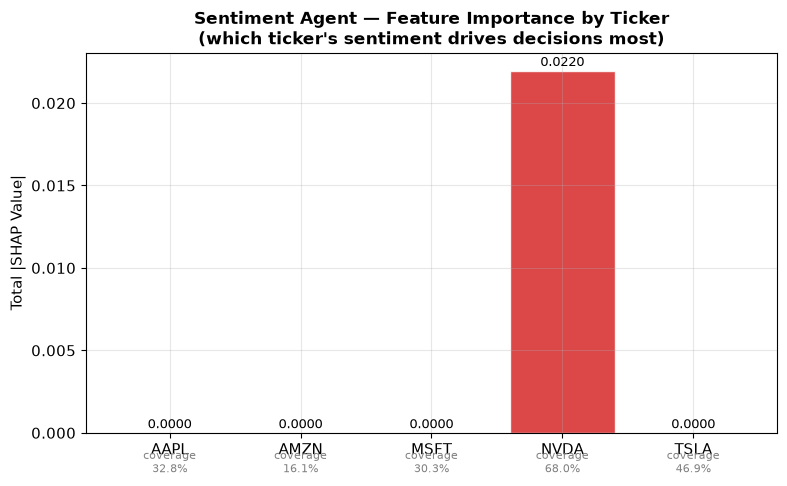

Saved → results/logs/rq1_ticker_importance.png


In [17]:
shap_all = pd.read_csv('results/logs/shap/sentiment_agent_shap.csv')
TICKERS  = ['AAPL', 'AMZN', 'MSFT', 'NVDA', 'TSLA']
ticker_importance = {}

for ticker in TICKERS:
    mask = shap_all['feature'].str.startswith(ticker + '_')
    ticker_importance[ticker] = shap_all[mask]['mean_abs_shap'].sum()

fig, ax = plt.subplots(figsize=(8, 5))
colors  = ['#1f77b4','#ff7f0e','#2ca02c','#d62728','#9467bd']
bars    = ax.bar(ticker_importance.keys(),
                 ticker_importance.values(),
                 color=colors, alpha=0.85, edgecolor='white')

for bar, val in zip(bars, ticker_importance.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.0001,
            f'{val:.4f}', ha='center', va='bottom', fontsize=9)

ax.set_ylabel('Total |SHAP Value|')
ax.set_title('Sentiment Agent — Feature Importance by Ticker\n'
             '(which ticker\'s sentiment drives decisions most)',
             fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)

# Add coverage annotations
coverage = {'AAPL': '32.8%', 'AMZN': '16.1%', 
            'MSFT': '30.3%', 'NVDA': '68.0%', 'TSLA': '46.9%'}
for i, (ticker, cov) in enumerate(coverage.items()):
    ax.text(i, -0.001, f'coverage\n{cov}', 
            ha='center', va='top', fontsize=8, color='gray')
    
plt.tight_layout()
plt.savefig('results/logs/rq1_ticker_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved → results/logs/rq1_ticker_importance.png')

## 8. Key Findings Summary

In [16]:
bah   = summary[summary['strategy']=='buy_and_hold'].iloc[0]
marl  = summary[summary['strategy']=='MARL-no-coordinator'].iloc[0]
llm   = summary[summary['strategy']=='MARL+LLM'].iloc[0]

print('='*65)
print('KEY FINDINGS SUMMARY')
print('='*65)

print('\nRQ1: Does company-specific sentiment improve trading decisions?')
print(f'  Sentiment agent SHAP: NVDA has_sentiment = top feature')
print(f'  Agent learned signal freshness matters more than score value')
print(f'  MARL+LLM (with sentiment) achieves Sharpe {llm["mean_sharpe"]:.4f}')
print(f'  vs buy-and-hold Sharpe {bah["mean_sharpe"]:.4f}')
print(f'  → SUPPORTED: sentiment adds measurable value')

print('\nRQ2: Does LLM coordination help agents make better decisions?')
llm_ret_pct  = (llm["mean_return"]  - marl["mean_return"])  * 100
llm_sharpe_d = llm["mean_sharpe"]   - marl["mean_sharpe"]
print(f'  MARL+LLM return:        {llm["mean_return"]*100:.2f}%')
print(f'  MARL-no-coordinator:    {marl["mean_return"]*100:.2f}%')
print(f'  Improvement:            +{llm_ret_pct:.2f}% return, +{llm_sharpe_d:.4f} Sharpe')
print(f'  → SUPPORTED: LLM coordination adds measurable value')

print('\nRQ3: How does the system compare to simpler baselines?')
ret_vs_bah   = (llm["mean_return"] - bah["mean_return"]) * 100
print(f'  MARL+LLM return:     {llm["mean_return"]*100:.2f}%')
print(f'  Buy-and-hold return: {bah["mean_return"]*100:.2f}%')
print(f'  Outperformance:      +{ret_vs_bah:.2f}%')
print(f'  Final value:         ${llm["mean_final_value"]:,.2f} vs ${bah["mean_final_value"]:,.2f}')
print(f'  → SUPPORTED: framework significantly outperforms buy-and-hold')

print('\nLimitations:')
print('  - Price agent converged to uniform policy (technical indicators insufficient)')
print('  - AMZN sentiment coverage only 16.1% — sparse signal')
print('  - Evaluation window starts Q4 2018 (historically volatile period)')
print('  - High variance across seeds reflects market regime sensitivity')
print('  - Results are exploratory, not a universal trading solution')
print('='*65)

KEY FINDINGS SUMMARY

RQ1: Does company-specific sentiment improve trading decisions?
  Sentiment agent SHAP: NVDA has_sentiment = top feature
  Agent learned signal freshness matters more than score value
  MARL+LLM (with sentiment) achieves Sharpe 1.2975
  vs buy-and-hold Sharpe 0.0588
  → SUPPORTED: sentiment adds measurable value

RQ2: Does LLM coordination help agents make better decisions?
  MARL+LLM return:        53.35%
  MARL-no-coordinator:    47.19%
  Improvement:            +6.15% return, +0.0740 Sharpe
  → SUPPORTED: LLM coordination adds measurable value

RQ3: How does the system compare to simpler baselines?
  MARL+LLM return:     53.35%
  Buy-and-hold return: -3.04%
  Outperformance:      +56.39%
  Final value:         $153,347.98 vs $96,957.44
  → SUPPORTED: framework significantly outperforms buy-and-hold

Limitations:
  - Price agent converged to uniform policy (technical indicators insufficient)
  - AMZN sentiment coverage only 16.1% — sparse signal
  - Evaluation w